In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

import numpy as np
import matplotlib.pyplot as plt

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

idx_train_7 = [i for i, (_, y) in enumerate(train_dataset) if y == 7]
train_7 = Subset(train_dataset, idx_train_7)

train_loader = DataLoader(train_7, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False)

print(f"Training samples of digit 7: {len(train_7)}")
print(f"Total test samples: {len(test_dataset)}")

Training samples of digit 7: 6265
Total test samples: 10000


In [3]:
class Encoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.net = nn.Sequential(
      nn.Flatten(),
      nn.Linear(28*28, 256),
      nn.ReLU(),
      nn.Linear(256, 128),
      nn.ReLU(),
      nn.Linear(128, 32)
    )

  def forward(self, x):
    return self.net(x)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = Encoder().to(device)

In [4]:
def compute_center(loader):
  model.eval()
  c = torch.zeros(32, device=device)
  n = 0

  with torch.no_grad():
    for x, _ in loader:
      x = x.to(device)
      z = model(x)
      c += z.sum(0)
      n += z.size(0)

  return c / n

c = compute_center(train_loader)

In [14]:
criterion = lambda z: torch.mean((z - c)**2)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 10
loss_history = []

for epoch in range(epochs):
  model.train()
  running_loss = 0

  for x, _ in train_loader:
    x = x.to(device)

    optimizer.zero_grad()
    z = model(x)
    loss = criterion(z)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * x.size(0)

  epoch_loss = running_loss / len(train_7)
  loss_history.append(epoch_loss)
  print(f"Epoch {epoch+1}/{epochs} — Loss: {epoch_loss}")

Epoch 1/10 — Loss: 1.1928185381363905e-06
Epoch 2/10 — Loss: 6.378055027054761e-08
Epoch 3/10 — Loss: 4.117568785675991e-08
Epoch 4/10 — Loss: 3.0809512229802605e-08
Epoch 5/10 — Loss: 2.3009031220962114e-08
Epoch 6/10 — Loss: 1.8271516834356994e-08
Epoch 7/10 — Loss: 1.4447043881290052e-08
Epoch 8/10 — Loss: 1.1538689378987029e-08
Epoch 9/10 — Loss: 9.31326810808324e-09
Epoch 10/10 — Loss: 7.916477327925903e-09


In [15]:
import joblib

joblib.dump(model, "model.joblib")

['model.joblib']

In [6]:
def anomaly_scores(loader):
  scores = []
  labels = []
  model.eval()

  with torch.no_grad():
    for x, y in loader:
      x = x.to(device)
      z = model(x)
      dist = torch.sum((z - c)**2, dim=1)

      scores.extend(dist.cpu().numpy())
      labels.extend(y.cpu().numpy())

  return np.array(scores), np.array(labels)

scores, labels = anomaly_scores(test_loader)

Digit 0: avg anomaly score = 2.9639910280820914e-05
Digit 1: avg anomaly score = 4.3761410779552534e-05
Digit 2: avg anomaly score = 5.0516286137280986e-05
Digit 3: avg anomaly score = 3.472457319730893e-05
Digit 4: avg anomaly score = 1.5004051419964526e-05
Digit 5: avg anomaly score = 3.919970913557336e-05
Digit 6: avg anomaly score = 4.277995685697533e-05
Digit 7: avg anomaly score = 4.788689238921506e-06
Digit 8: avg anomaly score = 2.5234643544536084e-05
Digit 9: avg anomaly score = 7.6752558015869e-06


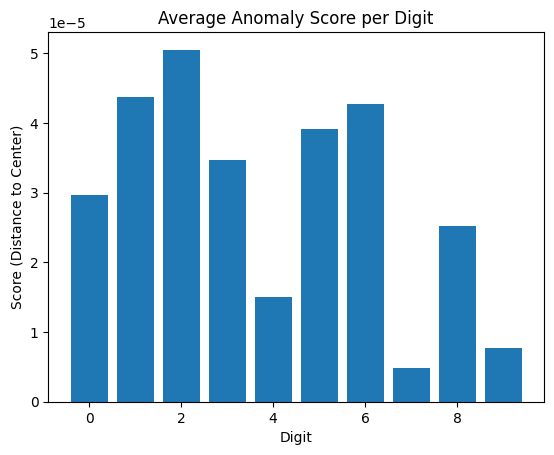

In [13]:
digit_means = {}

for digit in range(10):
  digit_scores = scores[labels == digit]
  digit_means[digit] = digit_scores.mean()
  print(f"Digit {digit}: avg anomaly score = {digit_scores.mean()}")

plt.bar(digit_means.keys(), digit_means.values())
plt.title("Average Anomaly Score per Digit")
plt.xlabel("Digit")
plt.ylabel("Score (Distance to Center)")
plt.show()

In [8]:
from sklearn.metrics import roc_auc_score

y_true = (labels == 7)
auc = roc_auc_score(y_true, -scores)
print("AUROC:", auc)

AUROC: 0.9128368022607298


In [10]:
from sklearn.metrics import roc_curve

fpr, tpr, thresh = roc_curve(labels == 7, -scores)
J = tpr - fpr
threshold = thresh[np.argmax(J)]
print(threshold)

-6.354474e-06


In [12]:
pred_is_7 = scores < threshold
accuracy = np.mean(pred_is_7 == (labels == 7))
print(accuracy)

0.8972
